# CrisisMMD v2.0 — All Three Tasks
## Multimodal Disaster Tweet Classification

| Task | Description | Labels |
|------|-------------|--------|
| **Task 1** | Informative vs Not Informative | informative, not_informative |
| **Task 2** | Humanitarian Categories | 7 classes |
| **Task 3** | Damage Severity Assessment | 4 classes |

**Dataset path (Kaggle):** `/kaggle/input/capstone-dataset/CrisisMMD_v2.0/`


## 0. Install Dependencies

In [88]:
!pip install -q open_clip_torch sentence-transformers faiss-cpu


## 1. Imports & Device Setup

In [89]:
import os, re, random
import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import torchvision.transforms as T
from transformers import (
    DistilBertTokenizerFast, DistilBertModel,
    CLIPProcessor, CLIPModel,
    AutoTokenizer
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, accuracy_score
)
import faiss
import open_clip

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")


Device: cuda


## 2. Dataset Paths

In [90]:
BASE        = Path("/kaggle/input/datasets/chhitanshushekhar/capstone-dataset/capstone_dataset/CrisisMMD_v2.0")
IMG_DIR     = BASE / "data_image"
SPLIT_DIR   = BASE / "crisismmd_datasplit_all" / "crisismmd_datasplit_all"
ANNOT_DIR   = BASE / "annotations"

# Task split files
TASK1_TRAIN = SPLIT_DIR / "task_informative_text_img_train.tsv"
TASK1_DEV   = SPLIT_DIR / "task_informative_text_img_dev.tsv"
TASK1_TEST  = SPLIT_DIR / "task_informative_text_img_test.tsv"

TASK2_TRAIN = SPLIT_DIR / "task_humanitarian_text_img_train.tsv"
TASK2_DEV   = SPLIT_DIR / "task_humanitarian_text_img_dev.tsv"
TASK2_TEST  = SPLIT_DIR / "task_humanitarian_text_img_test.tsv"

TASK3_TRAIN = SPLIT_DIR / "task_damage_text_img_train.tsv"
TASK3_DEV   = SPLIT_DIR / "task_damage_text_img_dev.tsv"
TASK3_TEST  = SPLIT_DIR / "task_damage_text_img_test.tsv"

print("Checking paths:")
for p in [BASE, IMG_DIR, SPLIT_DIR, ANNOT_DIR,
          TASK1_TRAIN, TASK2_TRAIN, TASK3_TRAIN]:
    print(f"  {'OK' if p.exists() else 'MISSING':7} {p}")


Checking paths:
  OK      /kaggle/input/datasets/chhitanshushekhar/capstone-dataset/capstone_dataset/CrisisMMD_v2.0
  OK      /kaggle/input/datasets/chhitanshushekhar/capstone-dataset/capstone_dataset/CrisisMMD_v2.0/data_image
  OK      /kaggle/input/datasets/chhitanshushekhar/capstone-dataset/capstone_dataset/CrisisMMD_v2.0/crisismmd_datasplit_all/crisismmd_datasplit_all
  OK      /kaggle/input/datasets/chhitanshushekhar/capstone-dataset/capstone_dataset/CrisisMMD_v2.0/annotations
  OK      /kaggle/input/datasets/chhitanshushekhar/capstone-dataset/capstone_dataset/CrisisMMD_v2.0/crisismmd_datasplit_all/crisismmd_datasplit_all/task_informative_text_img_train.tsv
  OK      /kaggle/input/datasets/chhitanshushekhar/capstone-dataset/capstone_dataset/CrisisMMD_v2.0/crisismmd_datasplit_all/crisismmd_datasplit_all/task_humanitarian_text_img_train.tsv
  OK      /kaggle/input/datasets/chhitanshushekhar/capstone-dataset/capstone_dataset/CrisisMMD_v2.0/crisismmd_datasplit_all/crisismmd_datasplit_

## 3. Shared Utilities (Text Cleaning + Helpers)

In [91]:
ABBREV_MAP = {
    r'\bpls\b': 'please', r'\bppl\b': 'people',
    r'\bw\/': 'with',    r'\bw/o\b': 'without',
    r'\bthx\b': 'thanks', r'\bplz\b': 'please',
    r'\bu\b': 'you',     r'\bur\b': 'your',
    r'\bgovt\b': 'government', r'\binfo\b': 'information',
}

def clean_tweet(text: str) -> str:
    if not isinstance(text, str):
        return ''
    text = re.sub(r'^RT\s+', '', text)
    text = re.sub(r'http\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+', '@user', text)
    text = re.sub(r'#(\w+)', r'\1', text)
    for pat, rep in ABBREV_MAP.items():
        text = re.sub(pat, rep, text, flags=re.IGNORECASE)
    return re.sub(r'\s+', ' ', text).strip()


def plot_confusion_matrix(y_true, y_pred, label_names, title='Confusion Matrix'):
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)
    short = [l[:18] for l in label_names]
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for ax, data, fmt, t in zip(axes, [cm, cm_norm], ['d', '.2f'],
                                 [f'{title} (counts)', f'{title} (row-norm)']):
        sns.heatmap(data, annot=True, fmt=fmt, cmap='Blues',
                    xticklabels=short, yticklabels=short, ax=ax)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(t)
        ax.tick_params(axis='x', rotation=40)
    plt.tight_layout(); plt.show()

print("Utilities ready.")


Utilities ready.


---
## ✅ Task 1 — Informative vs Not Informative

**Model:** TF-IDF + Logistic Regression (text-only baseline)  
**Labels:** `informative` | `not_informative`


In [92]:
# ── Load splits ───────────────────────────────────────────────────────────────
t1_train = pd.read_csv(TASK1_TRAIN, sep="\t").drop_duplicates(subset=["image_id"])
t1_dev   = pd.read_csv(TASK1_DEV,   sep="\t").drop_duplicates(subset=["image_id"])
t1_test  = pd.read_csv(TASK1_TEST,  sep="\t").drop_duplicates(subset=["image_id"])

t1_train["tweet_text"] = t1_train["tweet_text"].fillna("").apply(clean_tweet)
t1_dev["tweet_text"]   = t1_dev["tweet_text"].fillna("").apply(clean_tweet)
t1_test["tweet_text"]  = t1_test["tweet_text"].fillna("").apply(clean_tweet)

print(f"Task 1 — Train: {len(t1_train)} | Dev: {len(t1_dev)} | Test: {len(t1_test)}")
print("\nLabel distribution (Train):")
print(t1_train["label_text"].value_counts())


Task 1 — Train: 13608 | Dev: 2237 | Test: 2237

Label distribution (Train):
label_text
informative        9638
not_informative    3970
Name: count, dtype: int64


In [93]:
# ── Train ─────────────────────────────────────────────────────────────────────
t1_model = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=50_000, ngram_range=(1, 2),
                              sublinear_tf=True, min_df=2)),
    ("clf",   LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced")),
])
t1_model.fit(t1_train["tweet_text"], t1_train["label_text"])
print("Task 1 model trained.")


Task 1 model trained.


In [94]:
# ── Predict on Test ───────────────────────────────────────────────────────────
t1_test["predicted_label"] = t1_model.predict(t1_test["tweet_text"])

print("\n{:<25} {:<22} {}".format("tweet_id", "true_label", "predicted_label"))
print("-" * 72)
for _, row in t1_test.head(20).iterrows():
    print("{:<25} {:<22} {}".format(
        str(row["tweet_id"]), row["label_text"], row["predicted_label"]))



tweet_id                  true_label             predicted_label
------------------------------------------------------------------------
878185882431389696        not_informative        not_informative
906258753707790336        informative            informative
910542719864397824        informative            informative
906219963152785408        informative            informative
913009824195104768        informative            informative
916053383383011328        informative            not_informative
929989752400564226        informative            informative
922230253359116288        not_informative        informative
921368373765779456        not_informative        not_informative
904706043690745856        not_informative        informative
909865302481100802        not_informative        not_informative
917835421073031168        informative            informative
910089439770226689        not_informative        informative
910130660869730304        not_informative        inf

=== TASK 1 — TEST RESULTS ===
Accuracy : 0.7944
F1 (weighted): 0.7970

                 precision    recall  f1-score   support

not_informative       0.87      0.84      0.85      1612
    informative       0.62      0.68      0.65       625

       accuracy                           0.79      2237
      macro avg       0.75      0.76      0.75      2237
   weighted avg       0.80      0.79      0.80      2237



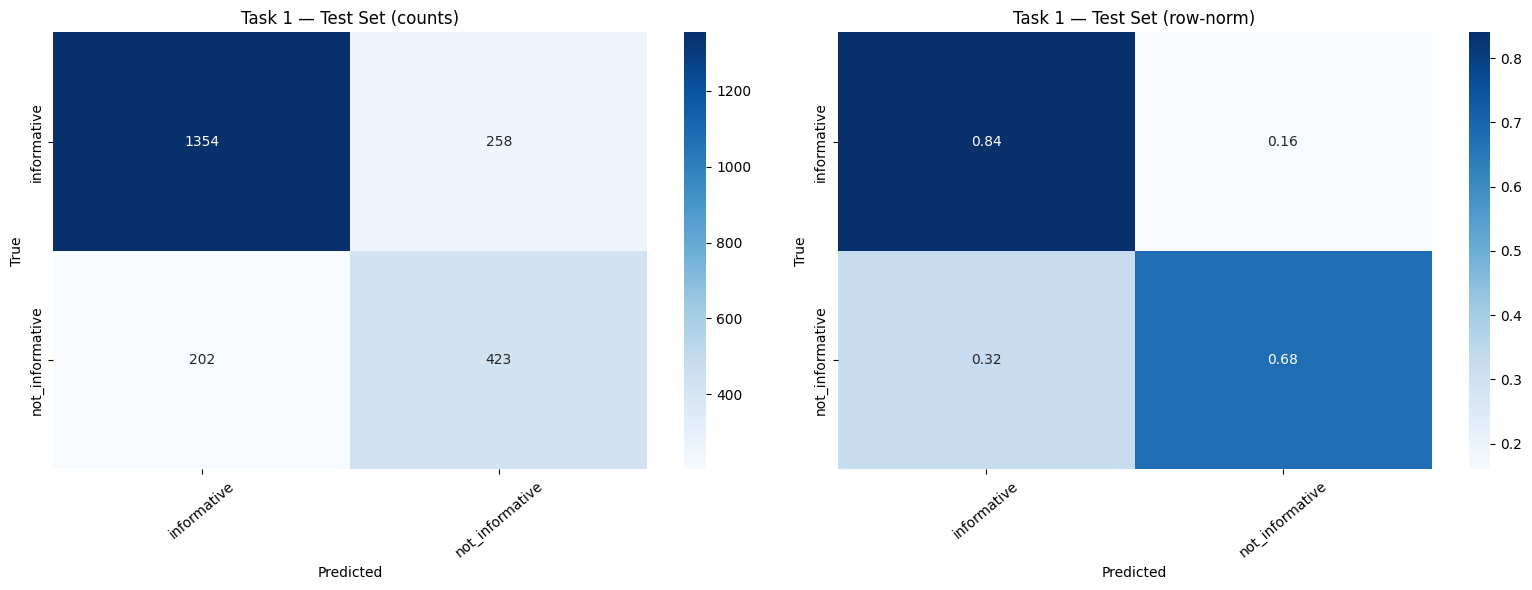

Saved → /kaggle/working/task1_predictions.csv


In [95]:
# ── Metrics ───────────────────────────────────────────────────────────────────
print("=== TASK 1 — TEST RESULTS ===")
print(f"Accuracy : {accuracy_score(t1_test['label_text'], t1_test['predicted_label']):.4f}")
print(f"F1 (weighted): {f1_score(t1_test['label_text'], t1_test['predicted_label'], average='weighted'):.4f}")
print()
print(classification_report(t1_test["label_text"], t1_test["predicted_label"],
                             target_names=["not_informative", "informative"]))

plot_confusion_matrix(t1_test["label_text"], t1_test["predicted_label"],
                      ["informative", "not_informative"], title="Task 1 — Test Set")

# Save
t1_test[["tweet_id", "tweet_text", "label_text", "predicted_label"]].to_csv(
    "/kaggle/working/task1_predictions.csv", index=False)
print("Saved → /kaggle/working/task1_predictions.csv")


---
## ✅ Task 2 — Humanitarian Categories

**Model:** CLIP (image) + DistilBERT (text) → Cross-Modal Attention → MLP  
**Labels:** Affected individuals | Infrastructure and utility damage | Injured or dead people | Missing or found people | Rescue, volunteering or donation effort | Vehicle damage | Other relevant information


In [96]:
# ── CLIP setup ────────────────────────────────────────────────────────────────
CLIP_MODEL_NAME = "ViT-B/32"
clip_model_t2, clip_preprocess_t2, _ = open_clip.create_model_and_transforms(
    CLIP_MODEL_NAME, pretrained='openai', device=DEVICE
)
print("CLIP loaded for Task 2.")


/usr/local/lib/python3.12/dist-packages/open_clip/factory.py:450: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


CLIP loaded for Task 2.


In [97]:
# ── Hyperparameters ───────────────────────────────────────────────────────────
T2_BATCH      = 32
T2_MAX_LEN    = 128
T2_LR         = 1e-4
T2_WARMUP     = 3
T2_EPOCHS     = 30
T2_IMG_SIZE   = 224
T2_D_MODEL    = 256
T2_ATTN_HEADS = 4
T2_DROPOUT    = 0.2


Task 2 — Train: 12124 | Dev: 1993 | Test: 1988
Classes (8): ['Affected individuals', 'Infrastructure and utility damage', 'Injured or dead people', 'Missing or found people', 'Not humanitarian', 'Other relevant information', 'Rescue, volunteering or donation effort', 'Vehicle damage']


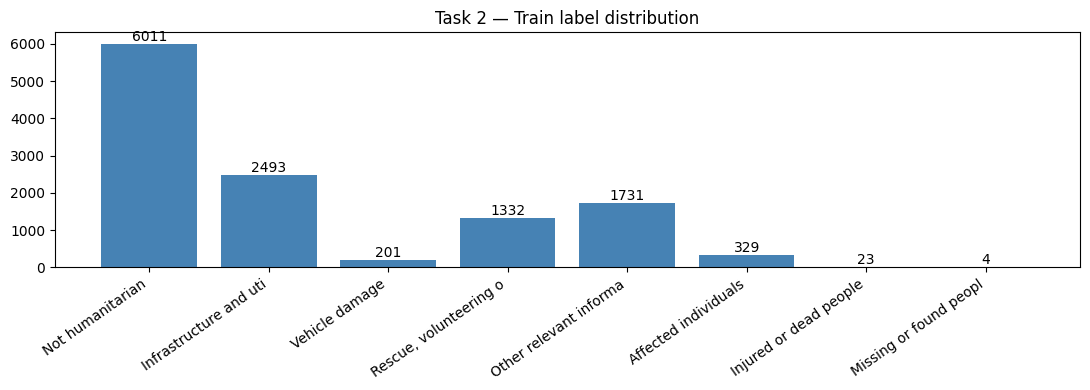

In [98]:
# ── Label normalisation ───────────────────────────────────────────────────────
T2_LABEL_MAP = {
    'affected_individuals':                    'Affected individuals',
    'affected_individuals_people':             'Affected individuals',
    'infrastructure_and_utility_damage':       'Infrastructure and utility damage',
    'infrastructure_and_utilities_damage':     'Infrastructure and utility damage',
    'vehicle_damage':                          'Vehicle damage',
    'rescue_volunteering_or_donation_effort':  'Rescue, volunteering or donation effort',
    'other_relevant_information':              'Other relevant information',
    'not_humanitarian':                        'Not humanitarian',
    'missing_or_found_people':                 'Missing or found people',
    'injured_or_dead_people':                  'Injured or dead people',
}

def t2_normalise(raw):
    if pd.isna(raw): return 'Unknown'
    key = str(raw).strip().lower().replace(' ', '_').replace('-', '_')
    return T2_LABEL_MAP.get(key, str(raw).strip())


def t2_load(tsv_path):
    df = pd.read_csv(tsv_path, sep='\t', dtype=str)
    df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')
    rename = {'tweet_text': 'text', 'text_info': 'text'}
    df = df.rename(columns={k: v for k, v in rename.items() if k in df.columns})
    df['label_text']  = df['label_text'].apply(t2_normalise)
    df['label_image'] = df['label_image'].apply(t2_normalise)

    def resolve_img(row):
        if pd.isna(row.get('image')): return None
        first = str(row['image']).split(',')[0].strip().lstrip('data_image/')
        full  = IMG_DIR / first
        return str(full) if full.exists() else None

    df['img_path'] = df.apply(resolve_img, axis=1)
    df = df[df['img_path'].notna()].copy()
    df = df[df['text'].notna() & (df['text'].str.strip() != '')].copy()
    df = df[df['label_text'] != 'Unknown'].copy()
    df['text']  = df['text'].apply(clean_tweet)
    df['label'] = df['label_image']
    return df.reset_index(drop=True)


t2_train = t2_load(TASK2_TRAIN)
t2_dev   = t2_load(TASK2_DEV)
t2_test  = t2_load(TASK2_TEST)

T2_ALL_LABELS = sorted(t2_train['label'].unique())
T2_L2I = {l: i for i, l in enumerate(T2_ALL_LABELS)}
T2_I2L = {i: l for l, i in T2_L2I.items()}
T2_NUM_CLASSES = len(T2_L2I)

print(f"Task 2 — Train: {len(t2_train)} | Dev: {len(t2_dev)} | Test: {len(t2_test)}")
print(f"Classes ({T2_NUM_CLASSES}):", T2_ALL_LABELS)

counts_t2 = Counter(t2_train['label'])
plt.figure(figsize=(11, 4))
bars = plt.bar([l[:22] for l in counts_t2], counts_t2.values(), color='steelblue')
plt.bar_label(bars); plt.xticks(rotation=35, ha='right')
plt.title('Task 2 — Train label distribution'); plt.tight_layout(); plt.show()


In [99]:
# ── Dataset class ─────────────────────────────────────────────────────────────
T2_TOKENIZER = DistilBertTokenizerFast.from_pretrained('distilbert-base-uncased')

class T2Dataset(Dataset):
    def __init__(self, df, transform, label2idx):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.label2idx = label2idx

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            img = Image.open(row['img_path']).convert('RGB')
        except Exception:
            img = Image.new('RGB', (T2_IMG_SIZE, T2_IMG_SIZE), (128, 128, 128))
        pixel_values = self.transform(img)

        enc = T2_TOKENIZER(str(row['text']), max_length=T2_MAX_LEN,
                           padding='max_length', truncation=True, return_tensors='pt')
        return (pixel_values,
                enc['input_ids'].squeeze(0),
                enc['attention_mask'].squeeze(0),
                torch.tensor(self.label2idx.get(row['label'], 0), dtype=torch.long))


t2_train_ds  = T2Dataset(t2_train, clip_preprocess_t2, T2_L2I)
t2_dev_ds    = T2Dataset(t2_dev,   clip_preprocess_t2, T2_L2I)
t2_test_ds   = T2Dataset(t2_test,  clip_preprocess_t2, T2_L2I)

t2_train_dl  = DataLoader(t2_train_ds, batch_size=T2_BATCH, shuffle=True,  num_workers=2, pin_memory=True)
t2_dev_dl    = DataLoader(t2_dev_ds,   batch_size=T2_BATCH, shuffle=False, num_workers=2, pin_memory=True)
t2_test_dl   = DataLoader(t2_test_ds,  batch_size=T2_BATCH, shuffle=False, num_workers=2, pin_memory=True)
print(f"DataLoaders — Train: {len(t2_train_dl)} | Dev: {len(t2_dev_dl)} | Test: {len(t2_test_dl)} batches")


DataLoaders — Train: 379 | Dev: 63 | Test: 63 batches


In [100]:
# ── Cross-Modal Attention Model ───────────────────────────────────────────────
class CrossModalAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        self.attn    = nn.MultiheadAttention(d_model, num_heads, dropout=dropout, batch_first=True)
        self.norm    = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, query, key_value, key_padding_mask=None):
        out, _ = self.attn(query, key_value, key_value, key_padding_mask=key_padding_mask)
        return self.norm(query + self.dropout(out))


class DualStreamClassifier(nn.Module):
    def __init__(self, num_classes, d_model=T2_D_MODEL, num_heads=T2_ATTN_HEADS, dropout=T2_DROPOUT):
        super().__init__()
        self.vision_encoder = clip_model_t2.visual
        for p in self.vision_encoder.parameters(): p.requires_grad = False

        img_dim = clip_model_t2.visual.output_dim
        self.img_proj = nn.Sequential(nn.Linear(img_dim, d_model), nn.LayerNorm(d_model))

        self.text_encoder = DistilBertModel.from_pretrained('distilbert-base-uncased')
        txt_dim = self.text_encoder.config.dim
        self.txt_proj = nn.Sequential(nn.Linear(txt_dim, d_model), nn.LayerNorm(d_model))

        self.img_to_txt = CrossModalAttention(d_model, num_heads, dropout)
        self.txt_to_img = CrossModalAttention(d_model, num_heads, dropout)

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(d_model * 2, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, num_classes),
        )

    def forward(self, pixels, input_ids, attn_mask):
        dtype = next(self.vision_encoder.parameters()).dtype
        img_vec  = self.img_proj(self.vision_encoder(pixels.to(dtype))).unsqueeze(1)
        txt_tok  = self.txt_proj(self.text_encoder(input_ids=input_ids,
                                                    attention_mask=attn_mask).last_hidden_state)
        txt_cls  = txt_tok[:, 0:1, :]
        pad_mask = (attn_mask == 0)

        img_att = self.img_to_txt(img_vec, txt_tok, pad_mask).squeeze(1)
        txt_att = self.txt_to_img(txt_cls, img_vec).squeeze(1)
        return self.classifier(torch.cat([img_att, txt_att], dim=-1))


t2_model = DualStreamClassifier(T2_NUM_CLASSES).to(DEVICE)
print(f"Task 2 model params: {sum(p.numel() for p in t2_model.parameters()):,}")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Task 2 model params: 155,202,056


In [101]:
# ── Training ──────────────────────────────────────────────────────────────────
label_counts_arr = np.array([counts_t2.get(T2_I2L[i], 1) for i in range(T2_NUM_CLASSES)], dtype=np.float32)
class_weights    = 1.0 / label_counts_arr
class_weights   /= class_weights.sum() / T2_NUM_CLASSES

t2_criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
)

t2_optimizer = optim.AdamW([
    {'params': t2_model.text_encoder.parameters(),  'lr': T2_LR * 0.1},
    {'params': t2_model.img_proj.parameters(),       'lr': T2_LR},
    {'params': t2_model.txt_proj.parameters(),       'lr': T2_LR},
    {'params': t2_model.img_to_txt.parameters(),     'lr': T2_LR},
    {'params': t2_model.txt_to_img.parameters(),     'lr': T2_LR},
    {'params': t2_model.classifier.parameters(),     'lr': T2_LR},
], weight_decay=1e-4)

t2_scheduler = optim.lr_scheduler.SequentialLR(
    t2_optimizer,
    schedulers=[
        optim.lr_scheduler.LinearLR(t2_optimizer, 1e-6, 1.0, T2_WARMUP),
        optim.lr_scheduler.CosineAnnealingLR(t2_optimizer, T_max=T2_EPOCHS - T2_WARMUP, eta_min=1e-7),
    ],
    milestones=[T2_WARMUP],
)

def t2_evaluate(loader, split='Val'):
    t2_model.eval()
    preds, labels, total_loss = [], [], 0.0
    with torch.no_grad():
        for imgs, ids, masks, lbl in loader:
            imgs, ids, masks, lbl = imgs.to(DEVICE), ids.to(DEVICE), masks.to(DEVICE), lbl.to(DEVICE)
            logits = t2_model(imgs, ids, masks)
            total_loss += t2_criterion(logits, lbl).item()
            preds.extend(logits.argmax(-1).cpu().numpy())
            labels.extend(lbl.cpu().numpy())
    acc = accuracy_score(labels, preds)
    f1  = f1_score(labels, preds, average='macro', zero_division=0)
    print(f"  [{split}] Loss={total_loss/len(loader):.4f}  Acc={acc:.4f}  MacroF1={f1:.4f}")
    return preds, labels


best_t2_f1 = 0.0
t2_history = {'train_loss': [], 'dev_f1': [], 'dev_acc': []}

for epoch in range(1, T2_EPOCHS + 1):
    t2_model.train()
    epoch_loss = 0.0
    pbar = tqdm(t2_train_dl, desc=f"[T2] Epoch {epoch}/{T2_EPOCHS}", leave=False)
    for imgs, ids, masks, lbl in pbar:
        imgs, ids, masks, lbl = imgs.to(DEVICE), ids.to(DEVICE), masks.to(DEVICE), lbl.to(DEVICE)
        t2_optimizer.zero_grad()
        loss = t2_criterion(t2_model(imgs, ids, masks), lbl)
        loss.backward()
        nn.utils.clip_grad_norm_(t2_model.parameters(), 1.0)
        t2_optimizer.step()
        epoch_loss += loss.item()
        pbar.set_postfix(loss=f"{loss.item():.4f}")
    t2_scheduler.step()

    avg_loss = epoch_loss / len(t2_train_dl)
    print(f"Epoch {epoch}/{T2_EPOCHS}  TrainLoss={avg_loss:.4f}")
    dev_preds, dev_labels = t2_evaluate(t2_dev_dl, 'Dev')

    f1 = f1_score(dev_labels, dev_preds, average='macro', zero_division=0)
    t2_history['train_loss'].append(avg_loss)
    t2_history['dev_f1'].append(f1)
    t2_history['dev_acc'].append(accuracy_score(dev_labels, dev_preds))

    if f1 > best_t2_f1:
        best_t2_f1 = f1
        torch.save(t2_model.state_dict(), '/kaggle/working/best_task2_model.pt')
        print(f"  ✓ New best MacroF1={f1:.4f} — checkpoint saved")

print(f"\nTask 2 training complete. Best Dev MacroF1: {best_t2_f1:.4f}")


[T2] Epoch 1/30:   0%|          | 0/379 [00:00<?, ?it/s]

Epoch 1/30  TrainLoss=2.1064


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  [Dev] Loss=2.0988  Acc=0.2423  MacroF1=0.0986
  ✓ New best MacroF1=0.0986 — checkpoint saved


[T2] Epoch 2/30:   0%|          | 0/379 [00:00<?, ?it/s]

...

[T2] Epoch 30/30:   0%|          | 0/379 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79f9e49ae020>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79f9e49ae020>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

Epoch 30/30  TrainLoss=0.0116


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79f9e49ae020>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79f9e49ae020>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packa

  [Dev] Loss=3.2571  Acc=0.7792  MacroF1=0.5478

Task 2 training complete. Best Dev MacroF1: 0.5741


  [Test] Loss=3.0711  Acc=0.7807  MacroF1=0.4696

=== TASK 2 — CLASSIFICATION REPORT ===
                                         precision    recall  f1-score   support

                   Affected individuals       0.46      0.36      0.41        72
      Infrastructure and utility damage       0.80      0.76      0.78       410
                 Injured or dead people       0.00      0.00      0.00         2
                Missing or found people       0.00      0.00      0.00         2
                       Not humanitarian       0.83      0.89      0.86       964
             Other relevant information       0.74      0.77      0.76       309
Rescue, volunteering or donation effort       0.70      0.54      0.61       196
                         Vehicle damage       0.33      0.36      0.35        33

                               accuracy                           0.78      1988
                              macro avg       0.48      0.46      0.47      1988
                  

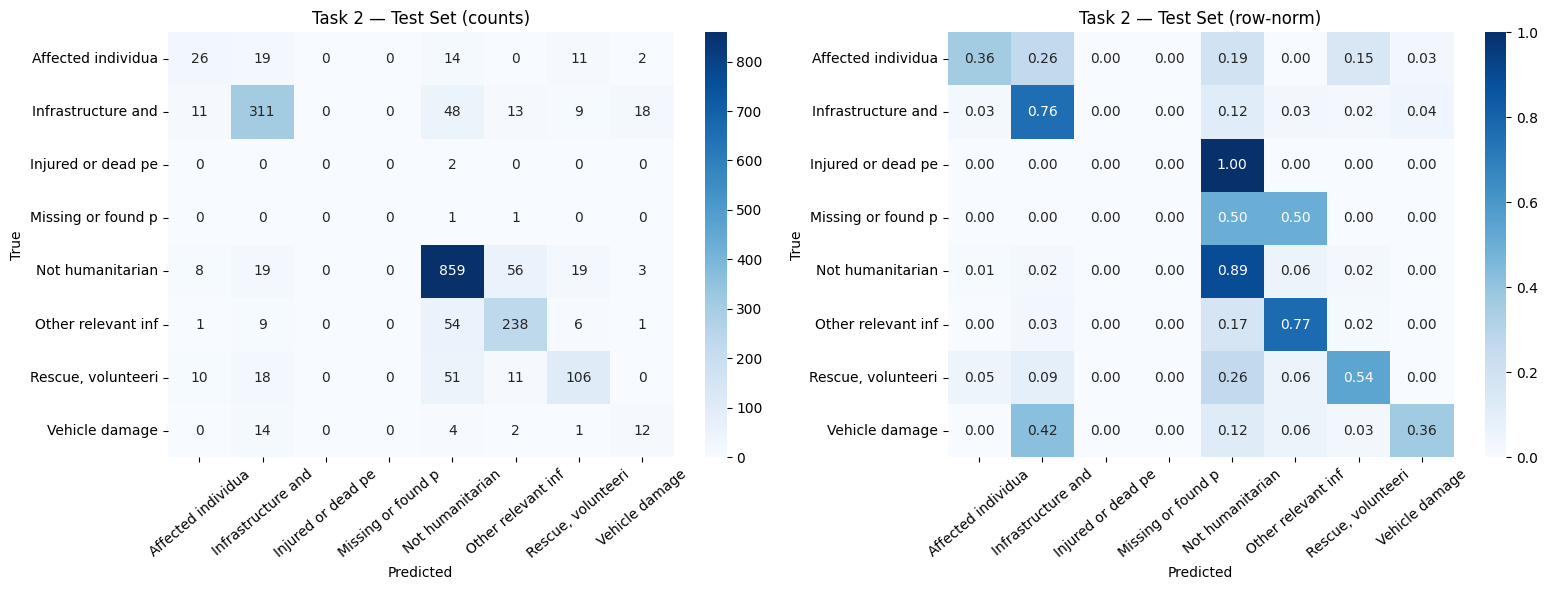

Saved → /kaggle/working/task2_predictions.csv


In [102]:
# ── Test evaluation ───────────────────────────────────────────────────────────
t2_model.load_state_dict(torch.load('/kaggle/working/best_task2_model.pt'))
t2_test_preds, t2_test_labels = t2_evaluate(t2_test_dl, 'Test')

T2_LABEL_NAMES = [T2_I2L[i] for i in range(T2_NUM_CLASSES)]
print("\n=== TASK 2 — CLASSIFICATION REPORT ===")
print(classification_report(t2_test_labels, t2_test_preds,
                             target_names=T2_LABEL_NAMES, zero_division=0))

plot_confusion_matrix(t2_test_labels, t2_test_preds,
                      T2_LABEL_NAMES, title='Task 2 — Test Set')

# Save predictions
t2_test_copy = t2_test.copy().reset_index(drop=True)
t2_test_copy['predicted_label'] = [T2_I2L[p] for p in t2_test_preds]
t2_test_copy['true_label']      = [T2_I2L[l] for l in t2_test_labels]
t2_test_copy[['tweet_id', 'text', 'true_label', 'predicted_label']].to_csv(
    '/kaggle/working/task2_predictions.csv', index=False)
print("Saved → /kaggle/working/task2_predictions.csv")


---
## ✅ Task 3 — Damage Severity Assessment

**Model:** CLIP image embeddings + Sentence-BERT text embeddings → FAISS retrieval → majority-vote prediction  
**Labels:** Severe damage | Mild damage | Little or no damage | Don't know or can't judge


In [103]:
# ── Label normalisation ───────────────────────────────────────────────────────
T3_DAMAGE_MAP = {
    'severe_damage':             'Severe damage',
    'mild_damage':               'Mild damage',
    'little_or_no_damage':       'Little or no damage',
    'no_damage':                 'Little or no damage',
    'none':                      'Little or no damage',
    'dont_know_or_cant_judge':   "Don't know or can't judge",
    'don_t_know_or_can_t_judge': "Don't know or can't judge",
    'dont_know':                 "Don't know or can't judge",
    'unknown':                   "Don't know or can't judge",
}

def t3_normalise(raw):
    if pd.isna(raw): return "Don't know or can't judge"
    key = str(raw).strip().lower().replace(' ', '_').replace('-', '_').replace('/', '_')
    return T3_DAMAGE_MAP.get(key, str(raw).strip())


def t3_load_annotations():
    dfs = []
    for f in os.listdir(ANNOT_DIR):
        if f.endswith('.tsv'):
            dfs.append(pd.read_csv(ANNOT_DIR / f, sep='\t'))
    df = pd.concat(dfs, ignore_index=True)

    df['tweet_text']    = df['tweet_text'].fillna('')
    df['image_damage']  = df['image_damage'].fillna('dont_know_or_cant_judge')
    df['damage_severity'] = df['image_damage'].apply(t3_normalise)
    df['image_full_path'] = df['image_path'].apply(lambda p: str(BASE / p) if isinstance(p, str) else None)
    df = df[df['image_full_path'].apply(lambda p: p is not None and os.path.exists(p))]
    df['clean_text'] = df['tweet_text'].apply(clean_tweet)
    return df.reset_index(drop=True)


t3_df = t3_load_annotations()
print(f"Task 3 — Total samples with valid images: {len(t3_df)}")
print("\nDamage severity distribution:")
print(t3_df['damage_severity'].value_counts())


Task 3 — Total samples with valid images: 18082

Damage severity distribution:
damage_severity
Don't know or can't judge    14556
Severe damage                 2212
Mild damage                    839
Little or no damage            475
Name: count, dtype: int64


In [104]:
# ── Text embeddings (Sentence-BERT) ──────────────────────────────────────────
from sentence_transformers import SentenceTransformer

T3_SBERT = SentenceTransformer("all-MiniLM-L6-v2")
T3_TEXT_DIM = 384

print("Generating Sentence-BERT embeddings...")
texts = [t if t.strip() else "no text" for t in t3_df['clean_text'].tolist()]
t3_text_embs = T3_SBERT.encode(texts, batch_size=64,
                                show_progress_bar=True, normalize_embeddings=True)
t3_df['text_embedding'] = list(t3_text_embs)
print(f"Text embeddings: {t3_text_embs.shape}")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Generating Sentence-BERT embeddings...


Batches:   0%|          | 0/283 [00:00<?, ?it/s]

Text embeddings: (18082, 384)


In [106]:
def get_clip_embeddings(paths, batch_size=64):
    all_embs = []

    for i in range(0, len(paths), batch_size):
        batch = []

        for p in paths[i:i+batch_size]:
            try:
                batch.append(Image.open(p).convert("RGB"))
            except:
                batch.append(Image.new("RGB", (224, 224)))

        inputs = T3_CLIP_PROC(images=batch, return_tensors="pt", padding=True).to(DEVICE)

        with torch.no_grad():
            output = T3_CLIP.get_image_features(**inputs)

        # 🔥 FIX HERE
        if isinstance(output, torch.Tensor):
            feats = output
        elif hasattr(output, "image_embeds"):
            feats = output.image_embeds
        elif hasattr(output, "pooler_output"):
            feats = output.pooler_output
        else:
            feats = output.last_hidden_state[:, 0, :]

        feats = feats / feats.norm(dim=-1, keepdim=True)

        all_embs.extend(feats.cpu().numpy())

        if (i // batch_size) % 10 == 0:
            print(f"{min(i+batch_size, len(paths))}/{len(paths)} images processed")

    return all_embs

print("Generating CLIP image embeddings...")
t3_img_embs = get_clip_embeddings(t3_df['image_full_path'].tolist())
t3_df['image_embedding'] = t3_img_embs
print(f"Image embeddings: {np.array(t3_img_embs).shape}")


Generating CLIP image embeddings...
64/18082 images processed
704/18082 images processed
1344/18082 images processed
1984/18082 images processed
2624/18082 images processed
3264/18082 images processed
3904/18082 images processed
4544/18082 images processed
5184/18082 images processed
5824/18082 images processed
6464/18082 images processed
7104/18082 images processed
7744/18082 images processed
8384/18082 images processed
9024/18082 images processed
9664/18082 images processed
10304/18082 images processed
10944/18082 images processed
11584/18082 images processed
12224/18082 images processed
12864/18082 images processed
13504/18082 images processed
14144/18082 images processed
14784/18082 images processed
15424/18082 images processed


/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


16064/18082 images processed
16704/18082 images processed
17344/18082 images processed
17984/18082 images processed
Image embeddings: (18082, 512)


In [107]:
# ── Build FAISS index ─────────────────────────────────────────────────────────
print("Building FAISS index...")
combined = np.array([
    np.concatenate([t3_df['image_embedding'].iloc[i],
                    t3_df['text_embedding'].iloc[i]])
    for i in range(len(t3_df))
], dtype='float32')

faiss.normalize_L2(combined)

T3_INDEX = faiss.IndexFlatIP(combined.shape[1])
T3_INDEX.add(combined)
print(f"FAISS index ready — {T3_INDEX.ntotal} vectors, dim={combined.shape[1]}")


Building FAISS index...
FAISS index ready — 18082 vectors, dim=896


In [109]:
# ── Retrieval & prediction ────────────────────────────────────────────────────
def t3_embed_query(image_path, text=""):
    try:
        img = Image.open(image_path).convert("RGB")
    except:
        img = Image.new("RGB", (224, 224))

    inputs = T3_CLIP_PROC(images=[img], return_tensors="pt").to(DEVICE)

    with torch.no_grad():
        output = T3_CLIP.get_image_features(**inputs)

    #  FIX: extract tensor
    if isinstance(output, torch.Tensor):
        feats = output
    elif hasattr(output, "image_embeds"):
        feats = output.image_embeds
    elif hasattr(output, "pooler_output"):
        feats = output.pooler_output
    else:
        feats = output.last_hidden_state[:, 0, :]

    # normalize
    feats = feats / feats.norm(dim=-1, keepdim=True)

    img_emb = feats.cpu().numpy().squeeze()

    # text embedding
    if text.strip():
        txt_emb = T3_SBERT.encode([clean_tweet(text)], normalize_embeddings=True)[0]
    else:
        txt_emb = np.zeros(T3_TEXT_DIM, dtype='float32')

    q = np.concatenate([img_emb, txt_emb]).reshape(1, -1).astype('float32')
    faiss.normalize_L2(q)

    return q


def t3_predict(image_path, text="", k=5):
    q = t3_embed_query(image_path, text)
    scores, indices = T3_INDEX.search(q, k)
    labels = [t3_df.iloc[i]['damage_severity'] for i in indices[0]]
    return max(set(labels), key=labels.count), labels, scores[0]


# ── Quick demo on a random sample ─────────────────────────────────────────────
sample = t3_df.sample(1).iloc[0]
pred, top_labels, scores = t3_predict(sample['image_full_path'], sample['clean_text'])
print(f"True label  : {sample['damage_severity']}")
print(f"Predicted   : {pred}")
print(f"Top-5 labels: {top_labels}")
print(f"Scores      : {scores.round(3)}")


True label  : Don't know or can't judge
Predicted   : Don't know or can't judge
Top-5 labels: ["Don't know or can't judge", "Don't know or can't judge", "Don't know or can't judge", "Don't know or can't judge", "Don't know or can't judge"]
Scores      : [1.    0.474 0.454 0.45  0.449]


Task 3 test split: 485 samples


Task 3 test:   0%|          | 0/485 [00:00<?, ?it/s]


=== TASK 3 — TEST RESULTS ===
Accuracy     : 0.6784
F1 (weighted): 0.6964

                           precision    recall  f1-score   support

            Severe damage       0.77      0.88      0.82       295
              Mild damage       0.82      0.33      0.47       120
      Little or no damage       0.85      0.40      0.54        70
Don't know or can't judge       0.00      0.00      0.00         0

                 accuracy                           0.68       485
                macro avg       0.61      0.40      0.46       485
             weighted avg       0.79      0.68      0.70       485



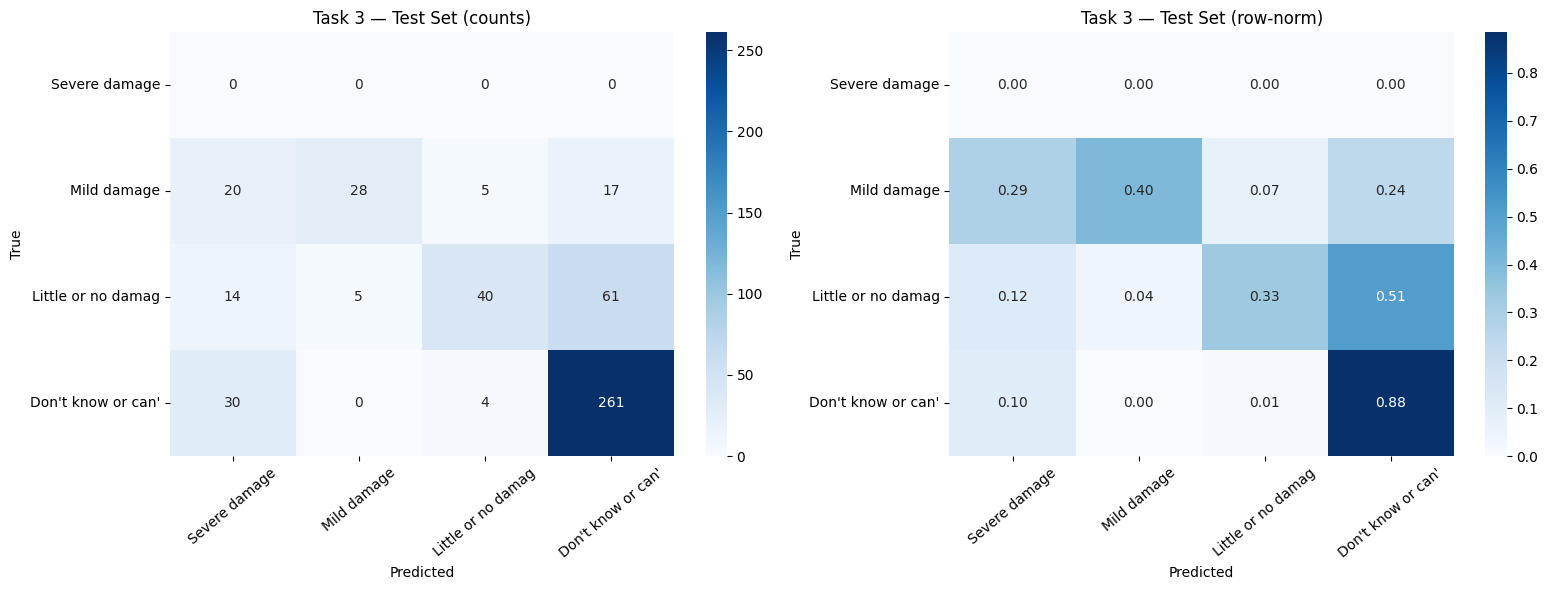

Saved → /kaggle/working/task3_predictions.csv


In [110]:
# ── Full test-set evaluation for Task 3 ──────────────────────────────────────
# Use the task_damage split files for a proper train/test evaluation
def t3_load_split(tsv_path):
    df = pd.read_csv(tsv_path, sep='\t', dtype=str)
    df.columns = df.columns.str.strip().str.lower()
    df['tweet_text'] = df.get('tweet_text', pd.Series(dtype=str)).fillna('')
    df['clean_text'] = df['tweet_text'].apply(clean_tweet)

    def resolve(row):
        img_col = row.get('image', '')
        if pd.isna(img_col): return None
        first = str(img_col).split(',')[0].strip().lstrip('data_image/')
        full  = IMG_DIR / first
        return str(full) if full.exists() else None

    df['img_path'] = df.apply(resolve, axis=1)
    df = df[df['img_path'].notna()].copy()

    # Use label_image for damage severity
    label_col = 'label_image' if 'label_image' in df.columns else 'label'
    df['damage_severity'] = df[label_col].apply(t3_normalise)
    return df.reset_index(drop=True)

t3_test_split = t3_load_split(TASK3_TEST)
print(f"Task 3 test split: {len(t3_test_split)} samples")

t3_true, t3_pred = [], []
for _, row in tqdm(t3_test_split.iterrows(), total=len(t3_test_split), desc="Task 3 test"):
    pred_label, _, _ = t3_predict(row['img_path'], row.get('clean_text', ''), k=5)
    t3_true.append(row['damage_severity'])
    t3_pred.append(pred_label)

print("\n=== TASK 3 — TEST RESULTS ===")
print(f"Accuracy     : {accuracy_score(t3_true, t3_pred):.4f}")
print(f"F1 (weighted): {f1_score(t3_true, t3_pred, average='weighted', zero_division=0):.4f}")
print()
T3_LABELS = ["Severe damage", "Mild damage", "Little or no damage", "Don't know or can't judge"]
print(classification_report(t3_true, t3_pred, labels=T3_LABELS,
                             target_names=T3_LABELS, zero_division=0))

plot_confusion_matrix(t3_true, t3_pred, T3_LABELS, title="Task 3 — Test Set")

# Save
t3_test_split['predicted_label'] = t3_pred
t3_test_split['true_label']      = t3_true
t3_test_split[['tweet_id', 'clean_text', 'true_label', 'predicted_label']].to_csv(
    '/kaggle/working/task3_predictions.csv', index=False)
print("Saved → /kaggle/working/task3_predictions.csv")


---
## 📊 Summary


In [111]:
print("=" * 60)
print("FINAL RESULTS SUMMARY")
print("=" * 60)

# Task 1
t1_acc = accuracy_score(t1_test['label_text'], t1_test['predicted_label'])
t1_f1  = f1_score(t1_test['label_text'], t1_test['predicted_label'], average='weighted')
print(f"Task 1 (Informative vs Not Informative)")
print(f"  Accuracy={t1_acc:.4f}  F1(weighted)={t1_f1:.4f}")

# Task 2
t2_acc_final = accuracy_score(t2_test_labels, t2_test_preds)
t2_f1_final  = f1_score(t2_test_labels, t2_test_preds, average='macro', zero_division=0)
print(f"Task 2 (Humanitarian Categories)")
print(f"  Accuracy={t2_acc_final:.4f}  MacroF1={t2_f1_final:.4f}")

# Task 3
t3_acc_final = accuracy_score(t3_true, t3_pred)
t3_f1_final  = f1_score(t3_true, t3_pred, average='weighted', zero_division=0)
print(f"Task 3 (Damage Severity)")
print(f"  Accuracy={t3_acc_final:.4f}  F1(weighted)={t3_f1_final:.4f}")

print("=" * 60)
print("Output files saved to /kaggle/working/")
print("  task1_predictions.csv")
print("  task2_predictions.csv")
print("  task3_predictions.csv")
print("  best_task2_model.pt")


FINAL RESULTS SUMMARY
Task 1 (Informative vs Not Informative)
  Accuracy=0.7944  F1(weighted)=0.7970
Task 2 (Humanitarian Categories)
  Accuracy=0.7807  MacroF1=0.4696
Task 3 (Damage Severity)
  Accuracy=0.6784  F1(weighted)=0.6964
Output files saved to /kaggle/working/
  task1_predictions.csv
  task2_predictions.csv
  task3_predictions.csv
  best_task2_model.pt
